# 01 — Limpieza y tabla base de mapas

## Objetivo

Construir la **tabla base** del proyecto: una fila por mapa válido, con sus identificadores,
los dos equipos, el marcador y la variable objetivo `team_a_win`, ordenada cronológicamente.

Para llegar ahí hay que: unir los seis años, asignar a cada mapa su ID, detectar y corregir
los problemas de calidad (duplicados, empates, mapas sin ID, mapas incompletos) y averiguar
**hasta qué punto los IDs sirven como orden temporal**, porque el dataset no trae fechas.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.config import INTERIM_DIR, TABLES_DIR
from src.data_loading import MAP_KEY, load_table, load_ids, clean_maps, build_maps_table
from src.plotting import set_style, save_fig

set_style()

## 1. Unir los seis años

`load_table` lee el mismo archivo de cada carpeta anual y agrega la columna `Year`.

In [2]:
scores = load_table("matches/maps_scores.csv")
ids = load_ids()
print("Mapas en maps_scores:", len(scores))
print("Filas en la tabla de IDs:", len(ids))
scores.isna().sum()

Mapas en maps_scores: 27484
Filas en la tabla de IDs: 27450


Tournament                   0
Stage                        0
Match Type                   0
Match Name                   0
Map                         41
Team A                       0
Team A Score                 0
Team A Attacker Score        0
Team A Defender Score        0
Team A Overtime Score    24997
Team B                       0
Team B Score                 0
Team B Attacker Score        0
Team B Defender Score        1
Team B Overtime Score    24997
Duration                   603
Year                         0
dtype: int64

Los únicos nulos están en las columnas de *overtime*, que solo aplican cuando el mapa se
alarga. No hay nulos en equipos ni marcadores.

A continuación se revisa cada problema de calidad por separado, contando cuántas filas afecta,
antes de corregirlo. Se lleva un registro de cuántas filas quedan tras cada paso.

In [3]:
log = [("Mapas originales", len(scores))]
key = MAP_KEY + ["Year"]   # torneo + etapa + tipo de partido + partido + mapa + año

## 2. Claves duplicadas

Un mapa se identifica por torneo, etapa, tipo de partido, nombre del partido y mapa. Si esa
combinación aparece más de una vez, no se puede saber a qué mapa corresponde cada ID.

In [4]:
dup_mask = scores.duplicated(key, keep=False)
print("Filas con clave duplicada, por año:")
print(dup_mask.groupby(scores["Year"]).sum().to_string())
scores[dup_mask].sort_values(key).head(6)[key + ["Team A Score", "Team B Score"]]

Filas con clave duplicada, por año:
Year
2021    45
2022     8
2023     0
2024     0
2025     0
2026     0


,Tournament,Stage,Match Type,Match Name,Map,Year,Team A Score,Team B Score
13491,Champions Tour Brazil Stage 1: Challengers 1,Open Qualifier,Round of 32,ChesterNo vs FURIA,NaN,2021,1,13
13492,Champions Tour Brazil Stage 1: Challengers 1,Open Qualifier,Round of 32,ChesterNo vs FURIA,NaN,2021,0,0
18307,Champions Tour Brazil Stage 1: Challengers 1,Open Qualifier #1,Round of 64,Utah Bless vs mira fofinha,Breeze,2022,13,6
18308,Champions Tour Brazil Stage 1: Challengers 1,Open Qualifier #1,Round of 64,Utah Bless vs mira fofinha,Breeze,2022,13,6
22561,Champions Tour Europe Stage 1: Challengers 1,Open Qualifier,Round of 256,Ignite Academy vs Victoire Gaming,Ascent,2022,13,8
22562,Champions Tour Europe Stage 1: Challengers 1,Open Qualifier,Round of 256,Ignite Academy vs Victoire Gaming,Ascent,2022,13,8


Son partidos entre los mismos equipos, en la misma etapa, que repitieron mapa (por ejemplo,
dos series distintas con el mismo nombre). Como son ambiguos y son muy pocos, **se eliminan
todas las filas involucradas** en lugar de adivinar cuál es cuál.

In [5]:
scores_step = scores[~dup_mask]
log.append(("Sin claves duplicadas", len(scores_step)))

## 3. Asignar IDs de partido y de mapa

Se cruza con la tabla de IDs por la misma clave. En la tabla de IDs también se descartan las
claves duplicadas para que el cruce no multiplique filas.

In [6]:
ids_unique = ids.drop_duplicates(key, keep=False)[key + ["Match ID", "Game ID"]]
merged = scores_step.merge(ids_unique, on=key, how="left")
assert len(merged) == len(scores_step)   # el cruce no crea filas

no_id = merged["Game ID"].isna() | merged["Match ID"].isna()
print("Mapas sin ID, por año:")
print(no_id.groupby(merged["Year"]).sum().to_string())

Mapas sin ID, por año:
Year
2021    17
2022    20
2023     0
2024     0
2025     0
2026     0


Sin ID no hay forma de ubicar el mapa en el tiempo, así que esos mapas se eliminan.

In [7]:
merged = merged[~no_id]
log.append(("Con ID asignado", len(merged)))

## 4. Empates y mapas incompletos

En Valorant un mapa no puede terminar empatado: gana el primero en llegar a 13 rondas (con
diferencia de 2 en *overtime*). Un empate o un ganador con menos de 13 rondas indica un error
de registro o un mapa que no se terminó.

In [8]:
ties = merged["Team A Score"] == merged["Team B Score"]
unfinished = ~ties & (merged[["Team A Score", "Team B Score"]].max(axis=1) < 13)
print("Empates por año:", ties.groupby(merged["Year"]).sum().to_dict())
print("Incompletos por año:", unfinished.groupby(merged["Year"]).sum().to_dict())
merged[ties | unfinished][["Year", "Match Name", "Map", "Team A Score", "Team B Score"]].head(8)

Empates por año: {2021: 10, 2022: 7, 2023: 0, 2024: 0, 2025: 0, 2026: 0}
Incompletos por año: {2021: 3, 2022: 1, 2023: 0, 2024: 0, 2025: 0, 2026: 0}


,Year,Match Name,Map,Team A Score,Team B Score
338,2021,Wildcard Gaming vs Team Bliss,Breeze,0,0
446,2021,GodLike Esports vs Lethal Esports,Ascent,7,3
1310,2021,Liberty vs Onlyfans,Ascent,16,16
2032,2021,Gen.G vs TSM,Split,20,20
2847,2021,Beşiktaş Esports vs FUT Esports,Split,17,17
4152,2021,ECM FCG eSports vs Team Plague,Icebox,0,0
4668,2021,Damianos Esport vs Easy Esports,Ascent,0,0
5704,2021,Mindfreak vs Nebula,Bind,0,0


In [9]:
merged = merged[~ties]
log.append(("Sin empates", len(merged)))
merged = merged[~unfinished[~ties]]
log.append(("Sin mapas incompletos", len(merged)))

## 5. Partidos de exhibición

Algunos torneos incluyen un *showmatch*: un partido de exhibición sin valor competitivo, a
veces con equipos mezclados. No representan el rendimiento real de un equipo y se eliminan.

In [10]:
showmatch = merged["Stage"] == "Showmatch"
print("Mapas de exhibición:", showmatch.sum())
merged = merged[~showmatch]
log.append(("Sin partidos de exhibición", len(merged)))

Mapas de exhibición: 5


## 6. Tabla base con la función compartida

Todos los pasos anteriores están reunidos en `clean_maps()` (archivo `src/data_loading.py`),
que además renombra las columnas, quita espacios sobrantes de los nombres de equipo, crea la
variable objetivo y ordena los mapas (el criterio de orden se explica en la sección siguiente). Se usa la función y se comprueba que da el mismo número de
filas que el paso a paso.

In [11]:
maps = build_maps_table()
assert len(maps) == len(merged)
assert maps["game_id"].is_unique
print(maps.shape)
maps.head()

(27368, 14)


,game_id,match_id,stage_block,year,tournament,stage,match_type,match_name,map,team_a,team_b,team_a_score,team_b_score,team_a_win
0,14718,8757,8757,2021,Champions Tour LATAM Stage 1: Challengers 1,Open Qualifier: LAS,Round of 16,Kaos Latin Gamers vs NoBordeR,Bind,Kaos Latin Gamers,NoBordeR,13,3,1
1,14719,8757,8757,2021,Champions Tour LATAM Stage 1: Challengers 1,Open Qualifier: LAS,Round of 16,Kaos Latin Gamers vs NoBordeR,Haven,Kaos Latin Gamers,NoBordeR,13,1,1
2,14721,8758,8757,2021,Champions Tour LATAM Stage 1: Challengers 1,Open Qualifier: LAS,Round of 16,Wygers Argentina vs Optix,Ascent,Wygers Argentina,Optix,9,13,0
3,14722,8758,8757,2021,Champions Tour LATAM Stage 1: Challengers 1,Open Qualifier: LAS,Round of 16,Wygers Argentina vs Optix,Bind,Wygers Argentina,Optix,13,6,1
4,14765,8758,8757,2021,Champions Tour LATAM Stage 1: Challengers 1,Open Qualifier: LAS,Round of 16,Wygers Argentina vs Optix,Haven,Wygers Argentina,Optix,13,2,1


Resumen de la limpieza:

In [12]:
summary = pd.DataFrame(log, columns=["step", "rows"])
summary["removed"] = -summary["rows"].diff().fillna(0).astype(int)
summary.to_csv(TABLES_DIR / "01_limpieza_resumen.csv", index=False)
print(f"Se conserva el {len(maps) / len(scores):.2%} de los mapas originales")
summary

Se conserva el 99.58% de los mapas originales


,step,rows,removed
0,Mapas originales,27484,0
1,Sin claves duplicadas,27431,53
2,Con ID asignado,27394,37
3,Sin empates,27377,17
4,Sin mapas incompletos,27373,4
5,Sin partidos de exhibición,27368,5


## 7. ¿Sirven los IDs como orden cronológico?

El supuesto inicial es que vlr.gg asigna los IDs de forma creciente, así que un `match_id`
mayor correspondería a un partido posterior. Como de este supuesto depende que el modelo no
use información del futuro, se pone a prueba en tres niveles: entre años, entre etapas de un
torneo y entre partidos de una misma etapa.

**a) Entre años: los rangos de ID no se solapan.**

In [13]:
ranges = maps.groupby("year")["match_id"].agg(["min", "max", "count"])
ranges["starts_after_previous_year"] = ranges["min"] > ranges["max"].shift(1).fillna(0)
ranges

,min,max,count,starts_after_previous_year
year,,,,
2021,8757,51296,14428,True
2022,60938,130691,8848,True
2023,167348,248283,830,True
2024,295605,378836,1104,True
2025,427991,542279,1272,True
2026,594740,684619,886,True


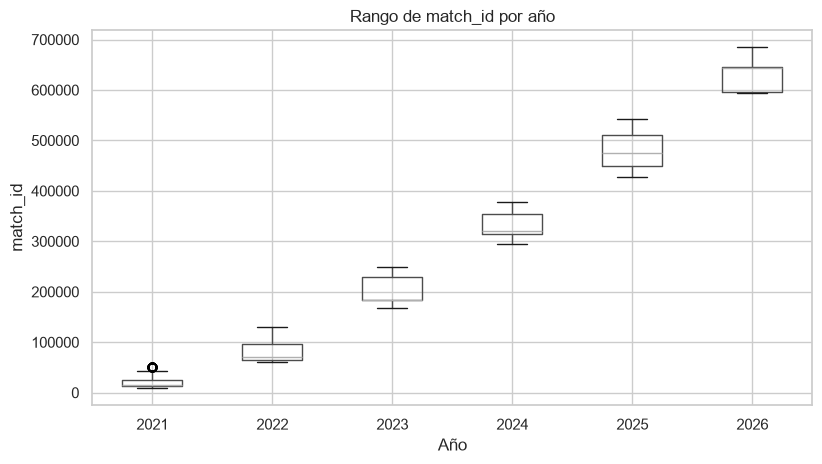

In [14]:
fig, ax = plt.subplots()
maps.boxplot(column="match_id", by="year", ax=ax)
ax.set(title="Rango de match_id por año", xlabel="Año", ylabel="match_id")
plt.suptitle("")
save_fig("01_match_id_por_anio")
plt.show()

**b) Entre etapas de un torneo.** Se listan las etapas de la temporada 2025 ordenadas por su
ID más bajo. El calendario real de VCT es conocido: *Kickoff* → Masters Bangkok → *Stage 1*
→ Masters Toronto → *Stage 2* → Champions, y dentro de cada torneo la fase de grupos va
antes que los *playoffs*.

In [15]:
stages = (maps.groupby(["year", "tournament", "stage"])["match_id"]
          .agg(first_id="min", last_id="max", maps="size").reset_index().sort_values("first_id"))
stages[stages["year"] == 2025][["tournament", "stage", "first_id", "last_id", "maps"]]

,tournament,stage,first_id,last_id,maps
542,VCT 2025: Americas Kickoff,Main Event,427991,428012,56
552,VCT 2025: EMEA Kickoff,Main Event,429379,429401,60
557,VCT 2025: Pacific Kickoff,Main Event,430514,430535,63
547,VCT 2025: China Kickoff,Main Event,430837,430860,56
565,Valorant Masters Bangkok 2025,Swiss Stage,448597,449005,23
564,Valorant Masters Bangkok 2025,Playoffs,449008,449013,19
548,VCT 2025: China Stage 1,Group Stage,450047,450076,75
558,VCT 2025: Pacific Stage 1,Group Stage,458805,458835,74
543,VCT 2025: Americas Stage 1,Group Stage,459517,459546,73
553,VCT 2025: EMEA Stage 1,Group Stage,459826,459857,73


El orden por ID reproduce el calendario real. Además se cuenta en cuántos torneos los rangos
de ID de dos etapas se pisan entre sí:

In [16]:
def overlapping_stages(group):
    group = group.sort_values("first_id")
    return (group["first_id"] < group["last_id"].cummax().shift(1)).any()

overlap = stages.groupby(["year", "tournament"])[["first_id", "last_id"]].apply(overlapping_stages)
overlap.groupby(level="year").agg(tournaments="size", with_overlap="sum")

,tournaments,with_overlap
year,,
2021,142,13
2022,58,5
2023,10,0
2024,15,1
2025,15,0
2026,10,0


Desde 2023 prácticamente no hay solapes; en 2021–2022 ocurre en una minoría de torneos
(clasificatorios con varias regiones en paralelo). **Entre etapas, el ID es un orden confiable.**

**c) Dentro de una etapa.** Se listan los *playoffs* de Valorant Champions 2024 ordenados
por ID. Es un cuadro de doble eliminación, así que la Gran Final tiene que ser el último partido.

In [17]:
champions = (maps[(maps["tournament"] == "Valorant Champions 2024") & (maps["stage"] == "Playoffs")]
             .groupby(["match_id", "match_type", "match_name"])["game_id"]
             .agg(first_game_id="min").reset_index())
champions

,match_id,match_type,match_name,first_game_id
0,378822,Upper Quarterfinals,DRX vs Sentinels,180414
1,378823,Upper Quarterfinals,Trace Esports vs EDward Gaming,180417
2,378824,Upper Quarterfinals,G2 Esports vs LEVIATÁN,180420
3,378825,Upper Quarterfinals,Team Heretics vs FNATIC,180423
4,378826,Upper Semifinals,Sentinels vs EDward Gaming,180426
5,378827,Upper Semifinals,LEVIATÁN vs Team Heretics,180429
6,378828,Upper Final,EDward Gaming vs LEVIATÁN,180432
7,378829,Grand Final,EDward Gaming vs Team Heretics,180435
8,378831,Lower Round 1,DRX vs Trace Esports,180440
9,378832,Lower Round 1,G2 Esports vs FNATIC,180443


**Aquí el supuesto falla.** La Gran Final aparece *antes* que toda la llave inferior, aunque
se jugó al final (uno de sus finalistas, Team Heretics, sale precisamente de la *Lower Final*).
Lo mismo pasa con los `game_id`. La explicación es que vlr.gg crea todas las casillas del
cuadro —con sus IDs— cuando se publica la etapa, no cuando se juega cada partido.

**Consecuencia:** si el historial de un equipo se calculara con "todos los partidos de ID
menor", un partido de la llave inferior vería el resultado de la Gran Final, que todavía no
había ocurrido. Sería fuga de datos.

**Decisión:** el orden solo se considera confiable *entre etapas*. Cada mapa recibe un
`stage_block` (el ID más bajo de su torneo + etapa) y, al construir variables, **el historial
de un equipo solo incluirá mapas de bloques anteriores**, nunca de la misma etapa. Se pierde
algo de información reciente, pero se garantiza que no se usa el futuro.

¿Cuánto historial se pierde? Se compara, para cada mapa, cuántos mapas previos tiene el
equipo con menos historial bajo cada criterio.

In [18]:
long = pd.concat([
    maps[["game_id", "year", "stage_block", "team_a"]].rename(columns={"team_a": "team"}),
    maps[["game_id", "year", "stage_block", "team_b"]].rename(columns={"team_b": "team"}),
]).sort_index(kind="stable")
long["prior_by_id"] = long.groupby("team").cumcount()
long["prior_by_block"] = long.groupby(["team", "stage_block"])["prior_by_id"].transform("min")

history = long.groupby("game_id").agg(year=("year", "first"), by_id=("prior_by_id", "min"),
                                      by_block=("prior_by_block", "min"))
history_summary = history.groupby("year").agg(
    median_prior_maps_by_id=("by_id", "median"),
    median_prior_maps_by_block=("by_block", "median"),
    share_without_history_by_id=("by_id", lambda s: (s == 0).mean()),
    share_without_history_by_block=("by_block", lambda s: (s == 0).mean()),
).round(3)
history_summary.to_csv(TABLES_DIR / "01_historial_por_criterio.csv")
history_summary

,median_prior_maps_by_id,median_prior_maps_by_block,share_without_history_by_id,share_without_history_by_block
year,,,,
2021,5.0,2.0,0.141,0.444
2022,8.0,4.0,0.100,0.398
2023,104.0,94.0,0.014,0.137
2024,134.0,131.0,0.005,0.027
2025,110.0,106.0,0.004,0.035
2026,118.5,114.0,0.006,0.055


De 2023 en adelante el costo es pequeño: los equipos son fijos y llegan a cada etapa con
alrededor de cien mapas de historial. En 2021–2022 el costo es alto, porque muchos equipos
solo jugaron un clasificatorio abierto y todo su recorrido ocurre dentro de una sola etapa.
Esos mapas quedarán con poco o ningún historial; se retoma en los cuadernillos 03 y 04.

## 8. Nombres de equipo

El historial de cada equipo se construirá agrupando por nombre, así que conviene saber qué
tan confiables son los nombres.

In [19]:
teams = pd.concat([maps["team_a"], maps["team_b"]])
print("Equipos distintos:", teams.nunique())

variants = (pd.DataFrame({"name": teams, "lower": teams.str.lower()})
            .drop_duplicates().groupby("lower")["name"].apply(list))
variants = variants[variants.str.len() > 1]
print("Nombres que solo difieren en mayúsculas:", len(variants))
variants.head(8)

Equipos distintos: 3970
Nombres que solo difieren en mayúsculas: 33


lower
anorthosis famagusta esports    [anorthosis famagusta esports, Anorthosis Fama...
aqua                                                                 [Aqua, aqua]
beatoffyou                                               [BEATOFFYOU, Beatoffyou]
bref                                                                 [Bref, bref]
down bad                                                     [down bad, Down Bad]
enigma                                                           [Enigma, ENIGMA]
envy                                                                 [Envy, ENVY]
equinox esports                                [Equinox Esports, Equinox eSports]
Name: name, dtype: object

Hay un puñado de nombres que solo cambian en mayúsculas/minúsculas. Entre casi 4 000 equipos
es una fracción mínima y no se puede saber si son el mismo equipo o dos equipos amateur con
nombre parecido, así que **se dejan como están**. Solo se eliminan los espacios sobrantes.

Los equipos por año muestran, otra vez, el cambio de formato de la competencia:

In [20]:
(pd.concat([maps[["year", "team_a"]].rename(columns={"team_a": "team"}),
            maps[["year", "team_b"]].rename(columns={"team_b": "team"})])
 .groupby("year")["team"].nunique().to_frame("teams").T)

year,2021,2022,2023,2024,2025,2026
teams,2733,1571,51,44,48,49


## 9. La variable objetivo

`team_a_win` vale 1 si el equipo listado como Team A ganó el mapa.

In [21]:
maps.groupby("year")["team_a_win"].agg(["mean", "size"]).round(3)

,mean,size
year,,
2021,0.583,14428
2022,0.587,8848
2023,0.511,830
2024,0.519,1104
2025,0.511,1272
2026,0.472,886


En 2021 y 2022 Team A gana bastante más de la mitad de los mapas. Como A y B son solo el
orden en que la web lista a los equipos, esto se analiza con cuidado en el cuadernillo 02.

## 10. Guardar

In [22]:
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
maps.to_csv(INTERIM_DIR / "maps.csv", index=False)
print("Guardado:", INTERIM_DIR / "maps.csv", maps.shape)

Guardado: C:\Users\JH\Hull\Trabajos U\S7 Ciencia de Datos\Proyecto\data\interim\maps.csv (27368, 14)


## Conclusiones

1. **Tabla base lista:** 27 368 mapas válidos de los 27 484 originales (se conserva el 99.58 %),
   guardados en `data/interim/maps.csv` con la variable objetivo `team_a_win`.
2. **Qué se eliminó y por qué:** 53 filas con clave duplicada (ambiguas), 37 mapas sin ID
   (no se pueden ubicar en el tiempo), 17 empates y 4 mapas incompletos (resultados
   imposibles en Valorant) y 5 mapas de exhibición. Todos los problemas están en 2021–2022,
   salvo los partidos de exhibición; de 2023 en adelante los datos vienen limpios.
3. **Hallazgo más importante — los IDs no son fechas:** ordenan bien los años y las etapas de
   un torneo, pero **no los partidos dentro de una etapa**. En los *playoffs* de Champions 2024
   la Gran Final tiene un ID menor que toda la llave inferior, porque la web crea las casillas
   del cuadro antes de que se jueguen.
4. **Decisión que condiciona el resto del proyecto:** el historial de un equipo solo usará
   mapas de **etapas anteriores** (`stage_block`), nunca de la misma etapa. Es la forma de
   garantizar que ninguna variable vea el futuro.
5. **Costo de esa decisión:** bajo en 2023–2026 (los equipos llegan a cada etapa con una
   mediana de 94 a 131 mapas previos), alto en 2021–2022 (mediana de 2 a 4 mapas, y cerca del
   40–45 % de los mapas tienen algún equipo sin historial).
6. **Nombres de equipo:** 3 979 equipos distintos; solo 33 nombres difieren en mayúsculas y
   se dejan como están. El historial se agrupará por nombre de equipo.
7. **Alerta para el siguiente paso:** Team A gana el 58 % de los mapas en 2021–2022 y cerca
   del 51 % después. Hay que entender por qué antes de modelar.

**Siguiente paso (cuadernillo 02):** análisis exploratorio de la tabla base.